> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M28-CD Javier Bueno Sanchez.

Objetivo: 

Aplicar PCA a Iris.csv, medir la varianza explicada por los dos primeros
componentes, interpretar los mapas de observaciones y factores, y corroborar los resultados
con casos concretos.

Indice

1. Datos y validacion.
2. Preparacion y verificacion del PCA.
3. Varianza explicada.
4. Mapa de observaciones.
5. Mapa de factores.
6. Comparacion y casos especificos.
7. Conclusiones.

1. Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

2. Preparacion y verificacion del PCA.

In [2]:
# URL directa del archivo Iris.csv
url = "https://gist.githubusercontent.com/netj/8836201/raw/iris.csv"

# Carga de los datos en un DataFrame
df = pd.read_csv(url)

# Visualización inicial
display(df.head())

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


El DataFrame muestra cinco variables:

- Cuatro variables numéricas: sepal.length, sepal.width, petal.length y petal.width.
- Una variable categórica: variety.
- Las primeras observaciones pertenecen a Setosa.

In [3]:
# Dimensiones y estructura del DataFrame
print(f"Dimensiones del DataFrame: {df.shape[0]} filas y {df.shape[1]} columnas")

print("\nInformación general:")
df.info()

print("\nValores nulos por columna:")
display(df.isnull().sum().to_frame(name="Valores nulos"))

print("\nDistribución de especies:")
display(df["variety"].value_counts().to_frame(name="Cantidad"))

Dimensiones del DataFrame: 150 filas y 5 columnas

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   variety       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Valores nulos por columna:


,Valores nulos
sepal.length,0
sepal.width,0
petal.length,0
petal.width,0
variety,0



Distribución de especies:


,Cantidad
variety,
Setosa,50
Versicolor,50
Virginica,50


La inspección confirma que la base está equilibrada y lista para analizar:

- 150 observaciones y 5 columnas.
- Cuatro variables numéricas aptas para PCA.
- Ningún valor nulo.
- Tres especies con 50 registros cada una.

In [4]:
# Verificación de filas duplicadas
duplicados = df.duplicated().sum()

print(f"Cantidad de filas duplicadas: {duplicados}")

if duplicados > 0:
    print("\nFilas identificadas como duplicadas:")
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))

Cantidad de filas duplicadas: 1

Filas identificadas como duplicadas:


,sepal.length,sepal.width,petal.length,petal.width,variety
101,5.8,2.7,5.1,1.9,Virginica
142,5.8,2.7,5.1,1.9,Virginica


Se conservan ambos registros. 

No existe un identificador que demuestre que se trata de la misma flor; dos observaciones distintas pueden compartir las mismas mediciones. 

Eliminarlas alteraría el equilibrio original de 50 registros por especie sin evidencia suficiente.

In [5]:
# Resumen estadístico de las variables numéricas
display(df.describe().round(2))

,sepal.length,sepal.width,petal.length,petal.width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


El resumen estadístico es correcto y coherente con la base Iris:

- Las variables tienen escalas y dispersiones distintas.
- petal.length presenta la mayor desviación estándar: 1.77.
- sepal.width presenta la menor: 0.44.
- Esto confirma que debemos estandarizar antes del PCA para evitar que las variables con mayor dispersión dominen el análisis.

3. Varianza explicada.

In [6]:
# Promedios de las variables numéricas por especie
promedios_especie = (df.groupby("variety").mean(numeric_only=True).round(2))

display(promedios_especie)

,sepal.length,sepal.width,petal.length,petal.width
variety,,,,
Setosa,5.01,3.43,1.46,0.25
Versicolor,5.94,2.77,4.26,1.33
Virginica,6.59,2.97,5.55,2.03


El resultado anticipa la estructura que debería revelar el PCA:

- Setosa: pétalos claramente más pequeños (1.46 de largo y 0.25 de ancho).
- Virginica: mayores dimensiones, especialmente en los pétalos (5.55 y 2.03).
- Versicolor: perfil intermedio.
- La anchura promedio del sépalo no sigue ese mismo orden: Setosa presenta el valor más alto (3.43).

In [7]:
# Selección de las variables numéricas para el PCA
variables = ["sepal.length","sepal.width","petal.length","petal.width"]

X = df[variables]

# Estandarización: media 0 y desviación estándar 1
escalador = StandardScaler()
X_estandarizado = escalador.fit_transform(X)

# Comprobación de la transformación
verificacion_estandarizacion = pd.DataFrame(
    {"Media": X_estandarizado.mean(axis=0),"Desviación estándar": X_estandarizado.std(axis=0)},
    index=variables)

display(verificacion_estandarizacion.round(4))

,Media,Desviación estándar
sepal.length,-0.0,1.0
sepal.width,-0.0,1.0
petal.length,-0.0,1.0
petal.width,-0.0,1.0


In [8]:
# Aplicación del PCA conservando los cuatro componentes
pca = PCA()
X_pca = pca.fit_transform(X_estandarizado)

# Tabla de varianza explicada
tabla_varianza = pd.DataFrame({"Componente": [f"PC{i}" for i in range(1, len(variables) + 1)],
        "Varianza explicada": pca.explained_variance_ratio_,
        "Varianza acumulada": np.cumsum(pca.explained_variance_ratio_)})

display(tabla_varianza.style.format(
        {"Varianza explicada": "{:.2%}","Varianza acumulada": "{:.2%}"}))

,Componente,Varianza explicada,Varianza acumulada
0,PC1,72.96%,72.96%
1,PC2,22.85%,95.81%
2,PC3,3.67%,99.48%
3,PC4,0.52%,100.00%


El resultado es:

- PC1: 72.96%
- PC2: 22.85%
- Varianza acumulada con dos componentes: 95.81%

Esto significa que se pueden representar las cuatro variables originales en un plano de dos dimensiones conservando casi toda la información. La pérdida es únicamente de 4.19%, por lo que la reducción es sólida y adecuada para interpretar los agrupamientos.

In [9]:
# Verificación de la varianza conservada por los dos primeros componentes
varianza_dos_componentes = pca.explained_variance_ratio_[:2].sum()

print(f"Varianza explicada por los dos primeros componentes: "
    f"{varianza_dos_componentes:.2%}")

assert varianza_dos_componentes > 0.90, ("Los dos primeros componentes no conservan más del 90% de la varianza.")

Varianza explicada por los dos primeros componentes: 95.81%


La verificación es:

- Los dos primeros componentes conservan 95.81% de la varianza.
- El assert se ejecutó sin errores, confirmando que supera el umbral del 90%.
- La reducción de cuatro variables a dos dimensiones está respaldada numéricamente.

In [10]:
# DataFrame con las coordenadas de cada observación en el plano PCA
df_pca = pd.DataFrame(X_pca[:, :2],columns=["PC1", "PC2"],index=df.index)

# Incorporación de la especie y del índice original
df_pca["variety"] = df["variety"]
df_pca["indice_original"] = df.index

display(df_pca.head())

,PC1,PC2,variety,indice_original
0,-2.264703,0.480027,Setosa,0
1,-2.080961,-0.674134,Setosa,1
2,-2.364229,-0.341908,Setosa,2
3,-2.299384,-0.597395,Setosa,3
4,-2.389842,0.646835,Setosa,4


El DataFrame df_pca quedó construido correctamente:

- PC1 y PC2 contienen las coordenadas de cada flor.
- variety conserva la especie.
- indice_original permite regresar al registro de origen.
- Las primeras observaciones de Setosa presentan valores negativos en PC1, anticipando que formarán un grupo diferenciado.

El signo negativo no representa un resultado desfavorable; únicamente indica la dirección de las observaciones dentro del eje PC1.

4. Mapa de observaciones.

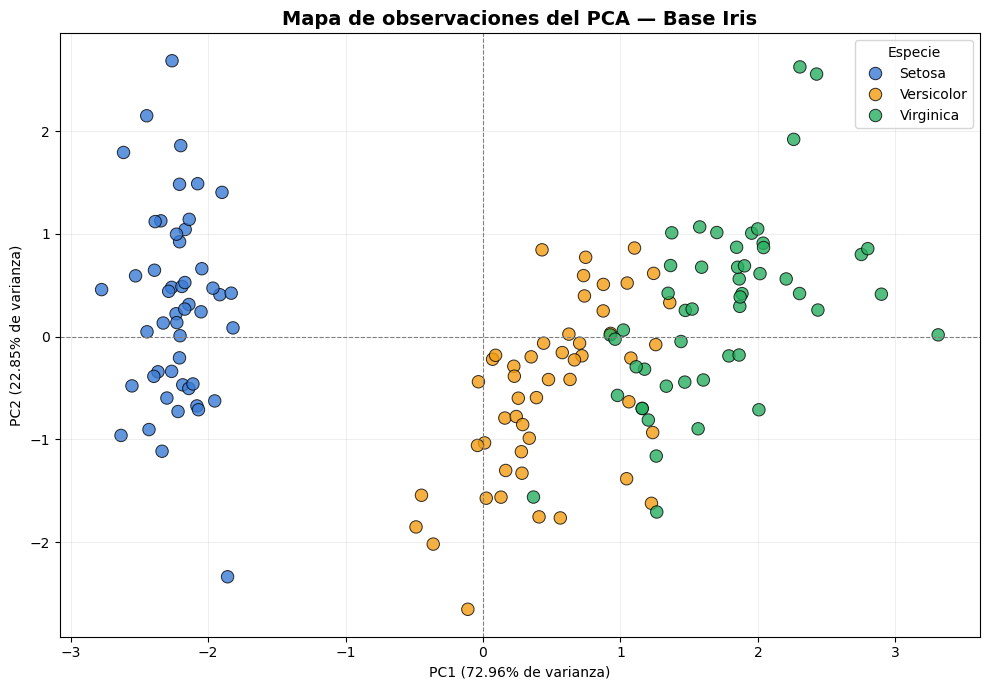

In [11]:
# Mapa de observaciones en los dos primeros componentes
plt.figure(figsize=(10, 7))

sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="variety", 
        palette={"Setosa": "#3A7BD5", "Versicolor": "#F39C12", "Virginica": "#27AE60"},
        s=80, alpha=0.80, edgecolor="black")

# Líneas de referencia en el origen
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title("Mapa de observaciones del PCA — Base Iris", fontsize=14, fontweight="bold")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%} de varianza)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%} de varianza)")

plt.legend(title="Especie")
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()

La gráfica confirma una estructura clara:

- Setosa queda completamente separada en valores negativos de PC1.
- Versicolor ocupa principalmente la zona central.
- Virginica se concentra en valores positivos de PC1.
- Existe cierto solapamiento entre Versicolor y Virginica, por lo que no todas las observaciones pueden distinguirse únicamente con los dos componentes.
- PC2 genera dispersión vertical dentro de cada especie, pero no produce una separación tan definida como PC1.

In [12]:
# Cálculo de las cargas o correlaciones entre variables y componentes
cargas = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])

tabla_cargas = pd.DataFrame(cargas, index=variables, columns=["PC1", "PC2"])

display(tabla_cargas.round(4))

,PC1,PC2
sepal.length,0.8932,0.3620
sepal.width,-0.4617,0.8857
petal.length,0.9949,0.0235
petal.width,0.9682,0.0642


La tabla de cargas permite interpretar los ejes con precisión:

- PC1 está fuertemente asociado con:
- petal.length: 0.9949
- petal.width: 0.9682
- sepal.length: 0.8932
- sepal.width se relaciona negativamente con PC1: −0.4617.
- PC2 está determinado principalmente por sepal.width: 0.8857.
- Las variables del pétalo tienen muy poca relación con PC2.

Por tanto:

- Valores altos de PC1 representan flores con pétalos largos y anchos, principalmente Virginica.
- Valores bajos de PC1 representan pétalos pequeños, característicos de Setosa.
- PC2 diferencia principalmente las observaciones según la anchura del sépalo.

5. Mapa de factores.

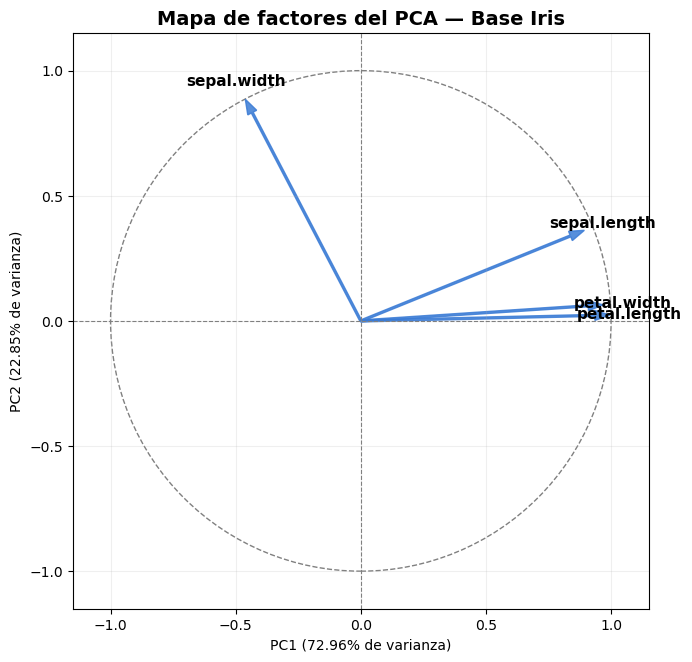

In [13]:
# Mapa de factores mediante un círculo de correlaciones
fig, ax = plt.subplots(figsize=(7, 7))

# Círculo de correlaciones
circulo = plt.Circle((0, 0), 1, color="gray", fill=False, linestyle="--", linewidth=1)

ax.add_patch(circulo)

# Vectores y nombres de las variables
for variable in variables:
    x = tabla_cargas.loc[variable, "PC1"]
    y = tabla_cargas.loc[variable, "PC2"]

    ax.arrow(0, 0, x, y, color="#3A7BD5", alpha=0.85, width=0.008, head_width=0.04, length_includes_head=True)

    ax.text(x * 1.08, y * 1.08, variable, fontsize=11, fontweight="bold", ha="center", va="center")

# Líneas de referencia
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal")

ax.set_title("Mapa de factores del PCA — Base Iris", fontsize=14, fontweight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%} de varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%} de varianza)")

ax.grid(alpha=0.20)
plt.tight_layout()
plt.show()

In [14]:
# Identificación de observaciones representativas en los extremos del PCA
indices_casos = {"PC1 mínimo": df_pca["PC1"].idxmin(), "PC1 máximo": df_pca["PC1"].idxmax(), "PC2 mínimo": df_pca["PC2"].idxmin(), "PC2 máximo": df_pca["PC2"].idxmax()}

# Construcción de una tabla con coordenadas PCA y datos originales
casos_especificos = []

for caso, indice in indices_casos.items():
    registro = {"Caso": caso, "Índice": indice, "Especie": df.loc[indice, "variety"], "PC1": df_pca.loc[indice, "PC1"], "PC2": df_pca.loc[indice, "PC2"],
        "sepal.length": df.loc[indice, "sepal.length"], "sepal.width": df.loc[indice, "sepal.width"], "petal.length": df.loc[indice, "petal.length"], 
        "petal.width": df.loc[indice, "petal.width"]}
    
    casos_especificos.append(registro)

casos_especificos = pd.DataFrame(casos_especificos)

display(casos_especificos.style.format(
        {"PC1": "{:.4f}", "PC2": "{:.4f}", "sepal.length": "{:.2f}", "sepal.width": "{:.2f}", "petal.length": "{:.2f}", "petal.width": "{:.2f}"}))

,Caso,Índice,Especie,PC1,PC2,sepal.length,sepal.width,petal.length,petal.width
0,PC1 mínimo,22,Setosa,-2.7743,0.4583,4.60,3.60,1.00,0.20
1,PC1 máximo,118,Virginica,3.3107,0.0178,7.70,2.60,6.90,2.30
2,PC2 mínimo,60,Versicolor,-0.1102,-2.6541,5.00,2.00,3.50,1.00
3,PC2 máximo,15,Setosa,-2.2622,2.6863,5.70,4.40,1.50,0.40


La tabla corrobora exactamente la interpretación de los mapas:

- PC1 mínimo — índice 22, Setosa: pétalos extremadamente pequeños (1.00 y 0.20). Confirma que los valores negativos de PC1 representan flores pequeñas, especialmente en el pétalo.
- PC1 máximo — índice 118, Virginica: pétalos muy grandes (6.90 y 2.30). Confirma la relación positiva de PC1 con el tamaño del pétalo.
- PC2 mínimo — índice 60, Versicolor: presenta el menor ancho de sépalo entre estos casos (2.00).
- PC2 máximo — índice 15, Setosa: posee un sépalo excepcionalmente ancho (4.40).

Por tanto, la evidencia del DataFrame respalda las cargas:

- PC1 ordena principalmente por el tamaño de los pétalos.
- PC2 diferencia principalmente por la anchura del sépalo.

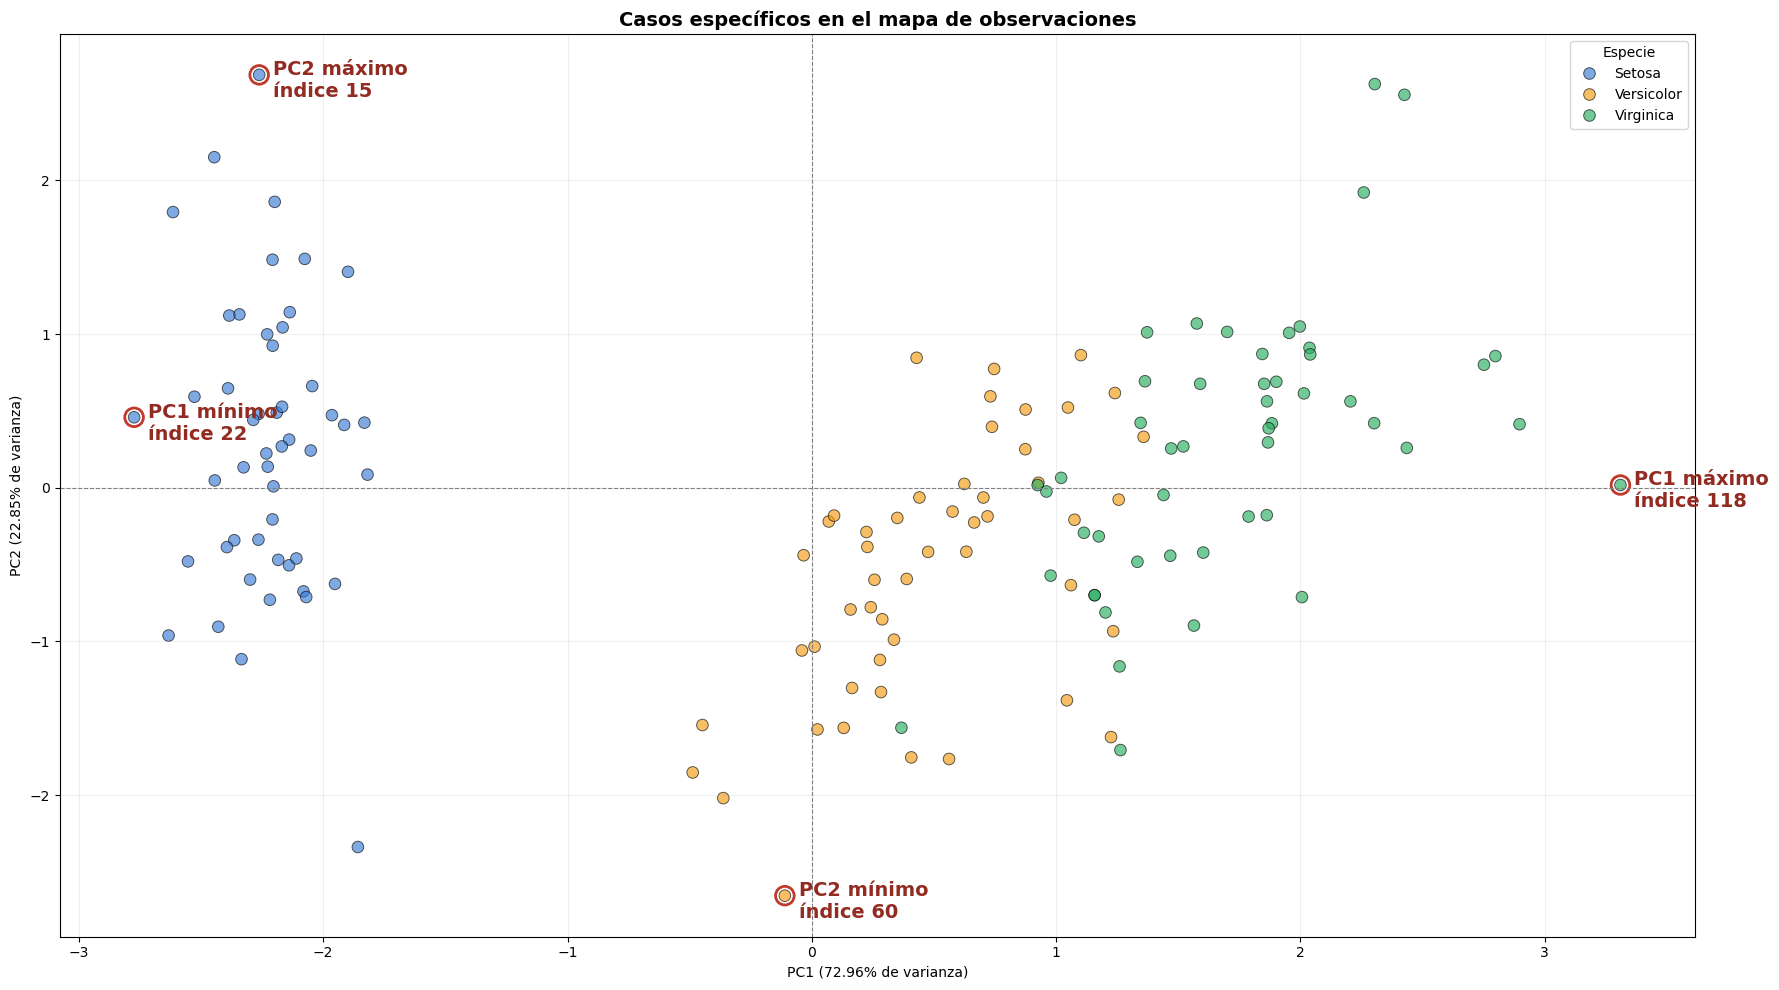

In [15]:
# Mapa de observaciones con los casos extremos identificados
plt.figure(figsize=(18, 10))

sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="variety",
    palette={"Setosa": "#3A7BD5", "Versicolor": "#F39C12", "Virginica": "#27AE60"}, s=70, alpha=0.65, edgecolor="black")

# Incorporación de los casos específicos
for caso, indice in indices_casos.items():
    x = df_pca.loc[indice, "PC1"]
    y = df_pca.loc[indice, "PC2"]

    plt.scatter(x, y, s=180, facecolors="none", edgecolors="#C0392B", linewidths=2)

    plt.annotate(f"{caso}\níndice {indice}", xy=(x, y), xytext=(10, -16), textcoords="offset points", fontsize=14, fontweight="bold", 
                 color="#922B21")

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title("Casos específicos en el mapa de observaciones", fontsize=14, fontweight="bold")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%} de varianza)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%} de varianza)")

plt.legend(title="Especie")
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()

6. Comparacion y casos especificos.

El mapa de observaciones muestra una separación clara de las especies principalmente a lo largo del primer componente principal. Setosa se concentra en valores negativos de PC1, Virginica ocupa predominantemente los valores positivos más altos y Versicolor se sitúa en una posición intermedia, con cierto solapamiento con Virginica.

El mapa de factores permite explicar esta distribución. Las variables `petal.length` y `petal.width` presentan una relación positiva muy fuerte con PC1, acompañadas por `sepal.length`. Por ello, las flores situadas hacia la derecha del mapa poseen, en general, pétalos más largos y anchos. En sentido contrario, las observaciones ubicadas hacia la izquierda presentan pétalos pequeños, característica distintiva de Setosa.

El segundo componente está asociado principalmente con `sepal.width`. Las observaciones situadas en la parte superior del mapa tienden a presentar sépalos más anchos, mientras que aquellas ubicadas en la parte inferior registran valores menores en esta variable.

La revisión de los casos extremos confirma esta interpretación:

- El índice 22, correspondiente a Setosa, presenta el valor mínimo de PC1 y pétalos de apenas 1.00 cm de largo y 0.20 cm de ancho.
- El índice 118, correspondiente a Virginica, alcanza el máximo de PC1 y posee pétalos de 6.90 cm de largo y 2.30 cm de ancho.
- El índice 60 presenta el mínimo de PC2 y un ancho de sépalo de 2.00 cm.
- El índice 15 registra el máximo de PC2 y un ancho de sépalo de 4.40 cm.

Por tanto, ambos mapas son coherentes y complementarios: el mapa de observaciones muestra cómo se agrupan las flores, mientras que el mapa de factores explica qué variables originan esa distribución.

7. Conclusiones.

El análisis de componentes principales permitió reducir las cuatro variables numéricas de la base Iris a dos componentes, conservando el **95.81% de la varianza total**. PC1 explica el **72.96%** y PC2 el **22.85%**, por lo que la representación bidimensional conserva prácticamente toda la estructura relevante de los datos.

PC1 está relacionado principalmente con el tamaño de los pétalos. Esta dimensión separa claramente a Setosa, caracterizada por pétalos pequeños, y sitúa a Virginica en el extremo opuesto por sus pétalos largos y anchos. Versicolor mantiene una posición intermedia, aunque presenta cierto solapamiento con Virginica.

PC2 está determinado principalmente por la anchura del sépalo. Este componente aporta una diferenciación vertical entre observaciones, pero su capacidad para separar especies es menor que la de PC1.

La comparación de los mapas demuestra que ambos cumplen funciones complementarias:

- El mapa de observaciones permite identificar agrupamientos, separaciones y solapamientos entre las especies.
- El mapa de factores explica qué variables originan esas posiciones.
- La revisión de los índices 22, 118, 60 y 15 confirma que la interpretación visual coincide con las mediciones originales.

En conclusión, el PCA ofrece una representación eficiente y comprensible de la base Iris. La separación entre especies depende principalmente de las dimensiones del pétalo, mientras que la anchura del sépalo explica buena parte de la variación secundaria. Sin embargo, el solapamiento observado entre Versicolor y Virginica indica que el PCA facilita la exploración y visualización de la estructura de los datos, pero no garantiza por sí solo una clasificación perfecta.